# BANK GOOD CREDIT PREDICTION
### Customer Credit-Risk Classification | Machine Learning Project

**Project objective:** Build and evaluate classification models that estimate whether a customer belongs to the Good Credit or Bad Credit class.

**Target variable:** `Bad_label`  
- `0` = Good Credit  
- `1` = Bad Credit

**Dataset:** `Data.csv` (1,000 records; 11 columns)

> **Important business note:** This notebook is an analytical prototype, not an automated lending decision system. Credit decisions require broader validation, fairness checks, regulatory review, and human oversight.

## 1. Project workflow

1. Import libraries and load the dataset
2. Inspect data quality and perform exploratory data analysis
3. Prepare features and target without using the customer identifier as a predictor
4. Split data using stratification
5. Build five classification models
6. Evaluate and compare model performance
7. Tune Gradient Boosting using cross-validation on training data only
8. Evaluate the tuned model on the held-out test set
9. Save the selected pipeline and summarize business implications

**Evaluation priority:** The Bad Credit class is expected to be the minority class. Therefore, accuracy will not be used alone. We will also inspect precision, recall, F1-score, ROC-AUC, and PR-AUC (average precision).

## 2. Import required libraries

In [3]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

## 3. Load the dataset

In [4]:
DATA_PATH = "Data.csv"

if not os.path.exists(r"C:\Users\91929\Downloads\Data.csv"):
    raise FileNotFoundError(
        "Data.csv was not found. Place Data.csv in the same folder as this notebook "
        "or update DATA_PATH with the correct file location."
    )

df = pd.read_csv(r"C:\Users\91929\Downloads\Data.csv")
print("Dataset loaded successfully.")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully.
Shape: (1000, 11)


,customer_no,Bad_label,total_accounts,total_balance,total_past_due,max_high_credit,total_credit_limit,avg_interest_rate,total_enquiries,total_enquiry_amount,avg_enquiry_amount
0,1,0,18,4714857.0,2538209.0,2528846.0,670000.0,17.712,18,4.981150e+06,2.767306e+05
1,2,0,2,30754.0,0.0,1000000.0,1000000.0,NaN,68,6.676682e+09,9.818650e+07
2,3,0,1,17864.0,0.0,121523.0,0.0,NaN,1,3.400000e+06,3.400000e+06
3,4,0,17,1845569.0,0.0,3000000.0,956000.0,23.935,34,5.081000e+07,1.494412e+06
4,5,0,7,7973.0,0.0,12662938.0,0.0,NaN,2,2.000000e+03,1.000000e+03


## 4. Initial data inspection

In [5]:
print("Column names:")
print(df.columns.tolist())

print("\\nDataset information:")
df.info()

print("\\nDescriptive statistics:")
display(df.describe().T)

print("\\nMissing values:")
display(df.isnull().sum().to_frame("Missing values"))

print("\\nDuplicate rows:", df.duplicated().sum())

print("\\nTarget values:")
display(df["Bad_label"].value_counts(dropna=False).sort_index())

Column names:
['customer_no', 'Bad_label', 'total_accounts', 'total_balance', 'total_past_due', 'max_high_credit', 'total_credit_limit', 'avg_interest_rate', 'total_enquiries', 'total_enquiry_amount', 'avg_enquiry_amount']
\nDataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   customer_no           1000 non-null   int64  
 1   Bad_label             1000 non-null   int64  
 2   total_accounts        1000 non-null   int64  
 3   total_balance         1000 non-null   float64
 4   total_past_due        1000 non-null   float64
 5   max_high_credit       1000 non-null   float64
 6   total_credit_limit    1000 non-null   float64
 7   avg_interest_rate     586 non-null    float64
 8   total_enquiries       1000 non-null   int64  
 9   total_enquiry_amount  1000 non-null   float64
 10  avg_enquiry_amount    995 non-n

,count,mean,std,min,25%,50%,75%,max
customer_no,1000.0,5.005000e+02,2.888194e+02,1.00,250.750000,5.005000e+02,7.502500e+02,1.000000e+03
Bad_label,1000.0,3.300000e-02,1.787259e-01,0.00,0.000000,0.000000e+00,0.000000e+00,1.000000e+00
total_accounts,1000.0,8.582000e+00,6.922948e+00,1.00,4.000000,7.000000e+00,1.100000e+01,6.600000e+01
total_balance,1000.0,9.198987e+05,3.701384e+06,-9912.00,37706.250000,1.656600e+05,4.932092e+05,6.069924e+07
total_past_due,1000.0,5.431092e+03,1.063023e+05,0.00,0.000000,0.000000e+00,0.000000e+00,2.538209e+06
max_high_credit,1000.0,1.040342e+06,3.727162e+06,3939.00,87801.500000,2.065000e+05,5.250000e+05,7.055562e+07
total_credit_limit,1000.0,2.019175e+05,2.899356e+05,0.00,51500.000000,1.200000e+05,2.482500e+05,4.575000e+06
avg_interest_rate,586.0,2.946943e+01,1.160890e+01,1.73,19.705000,3.500000e+01,3.943800e+01,4.500000e+01
total_enquiries,1000.0,1.834500e+01,1.515585e+01,1.00,8.000000,1.400000e+01,2.500000e+01,1.170000e+02
total_enquiry_amount,1000.0,4.597487e+07,3.879278e+08,0.00,466496.750000,1.765000e+06,4.774276e+06,6.836382e+09


\nMissing values:


,Missing values
customer_no,0
Bad_label,0
total_accounts,0
total_balance,0
total_past_due,0
max_high_credit,0
total_credit_limit,0
avg_interest_rate,414
total_enquiries,0
total_enquiry_amount,0


\nDuplicate rows: 0
\nTarget values:


Bad_label
0    967
1     33
Name: count, dtype: int64

## 5. Exploratory Data Analysis (EDA)

EDA helps understand the target distribution, feature ranges, missing values, and possible relationships. The charts below are descriptive; they do not establish causation.

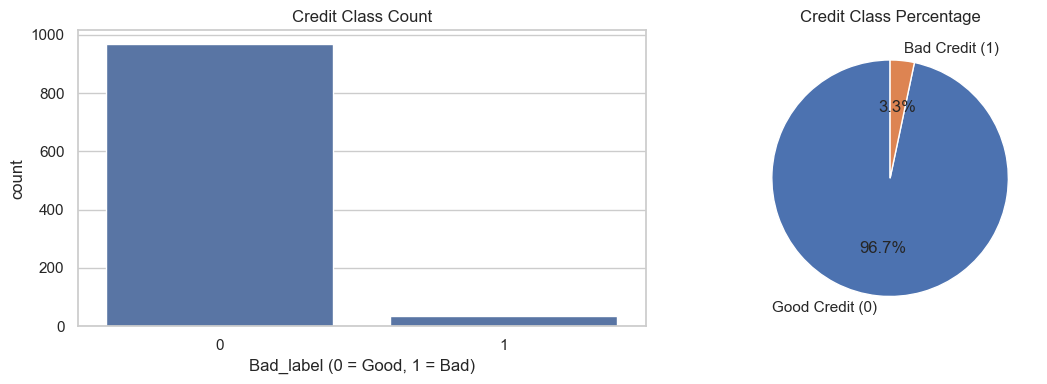

,Count,Percentage
Bad_label,,
0,967,96.7
1,33,3.3


In [6]:
# Target class distribution
target_counts = df["Bad_label"].value_counts().sort_index()
target_pct = df["Bad_label"].value_counts(normalize=True).sort_index() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="Bad_label", ax=axes[0])
axes[0].set_title("Credit Class Count")
axes[0].set_xlabel("Bad_label (0 = Good, 1 = Bad)")
axes[1].pie(target_counts.values, labels=["Good Credit (0)", "Bad Credit (1)"],
            autopct="%1.1f%%", startangle=90)
axes[1].set_title("Credit Class Percentage")
plt.tight_layout()
plt.show()

display(pd.DataFrame({"Count": target_counts, "Percentage": target_pct.round(2)}))

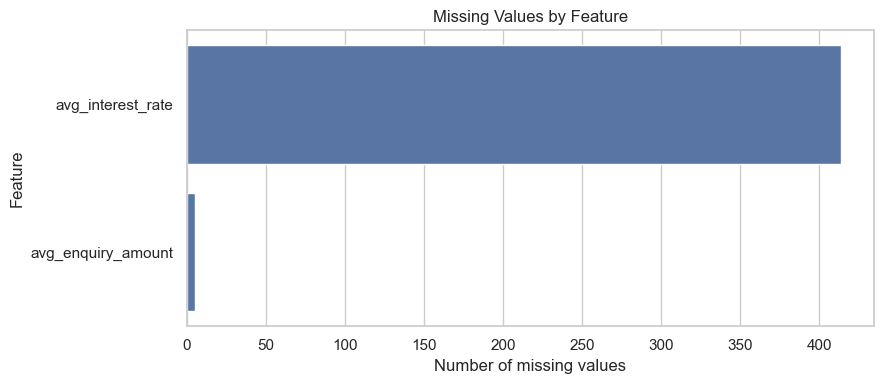

In [7]:
# Missing-value visualization
missing = df.isnull().sum().sort_values(ascending=False)
missing = missing[missing > 0]
if len(missing):
    plt.figure(figsize=(9, 4))
    sns.barplot(x=missing.values, y=missing.index)
    plt.title("Missing Values by Feature")
    plt.xlabel("Number of missing values")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")

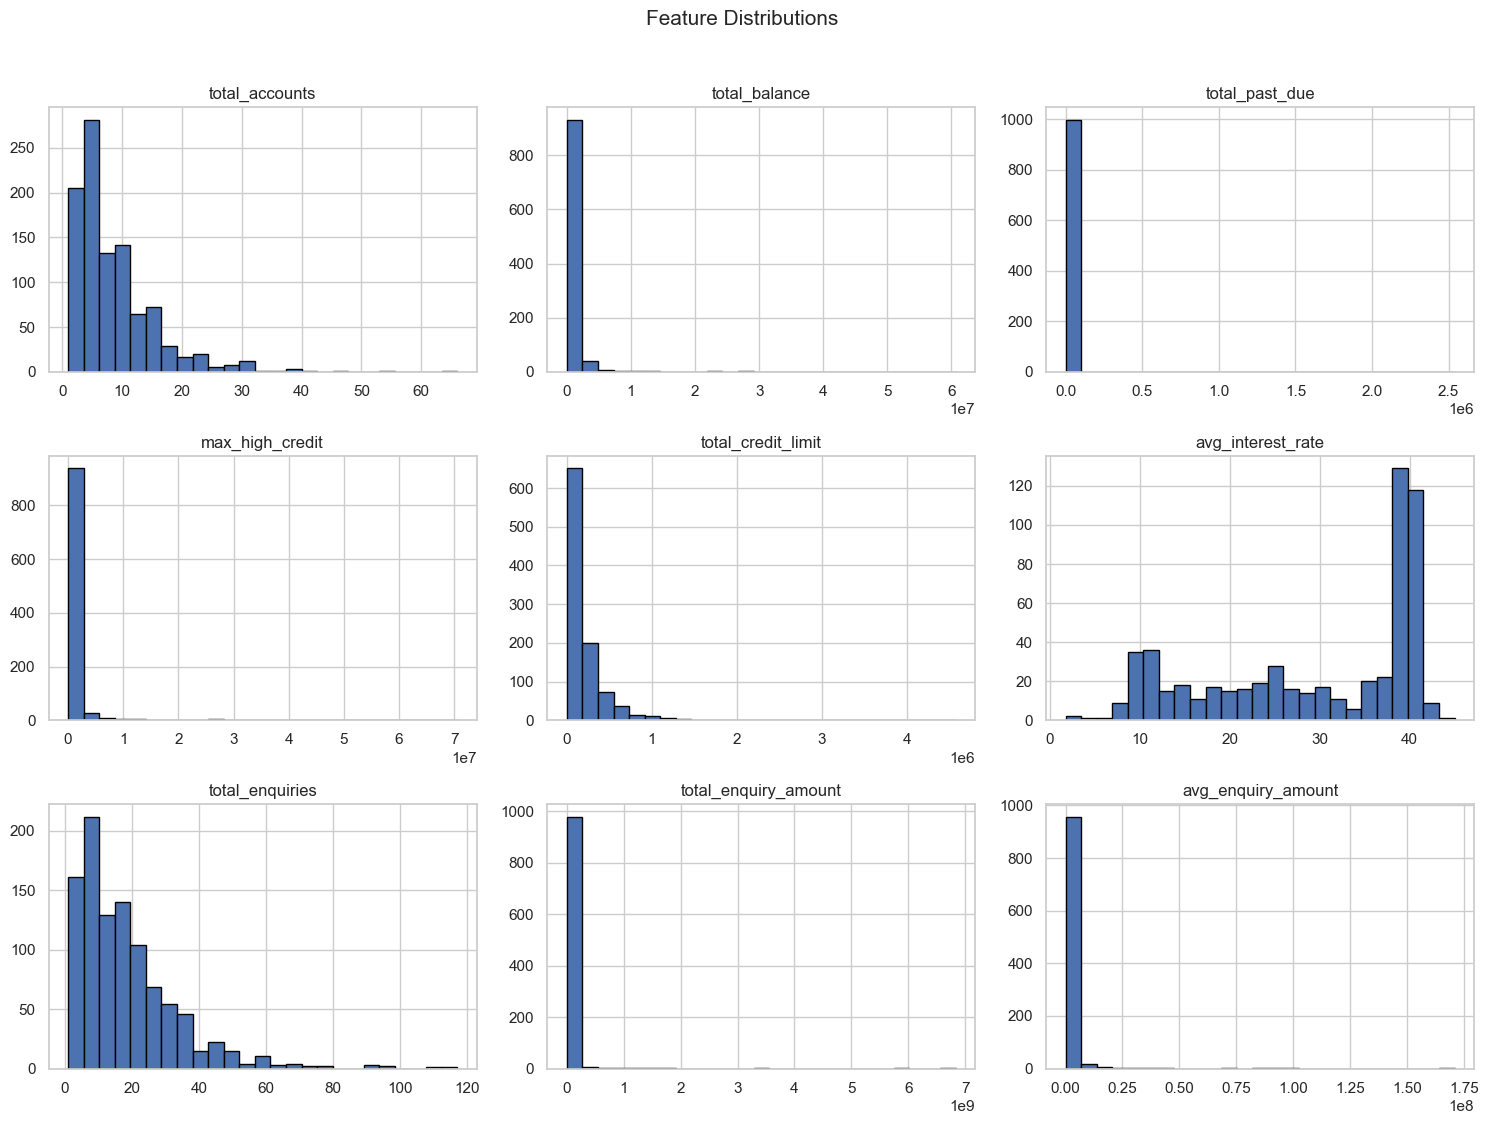

In [8]:
# Numeric feature distributions (identifier and target excluded)
numeric_for_eda = df.drop(columns=["customer_no", "Bad_label"], errors="ignore").select_dtypes(include=np.number)
numeric_for_eda.hist(figsize=(15, 11), bins=25, edgecolor="black")
plt.suptitle("Feature Distributions", y=1.02, fontsize=15)
plt.tight_layout()
plt.show()

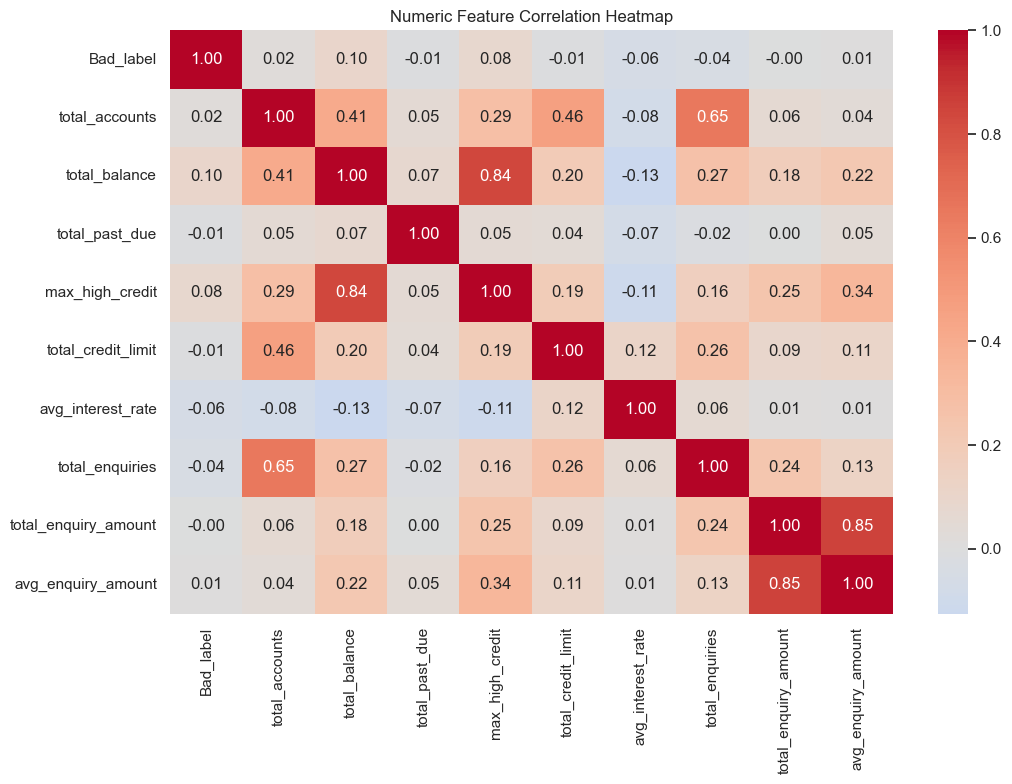

In [9]:
# Correlation heatmap
corr_data = df.select_dtypes(include=np.number).drop(columns=["customer_no"], errors="ignore")
plt.figure(figsize=(11, 8))
sns.heatmap(corr_data.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Numeric Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

## 6. Data quality decisions and preprocessing

- `customer_no` is a unique customer identifier, so it is excluded from model features to avoid learning from an arbitrary ID.
- Missing numeric values are imputed with the **median** inside a pipeline. This ensures imputation is learned from training data only.
- Standardization is applied to KNN and Logistic Regression because these algorithms are sensitive to feature scale.
- Tree-based models do not require feature standardization, but they still use the imputation pipeline.
- Negative or unusually large financial values should be investigated with the data owner. They are not automatically deleted or changed here.
- No synthetic oversampling is applied by default because the minority class is small. Class imbalance is instead addressed through suitable metrics and class-weight options where supported.

In [10]:
# Validate target and prepare X/y
if "Bad_label" not in df.columns:
    raise KeyError("Target column 'Bad_label' was not found.")

if df["Bad_label"].isna().any():
    raise ValueError("The target column contains missing values. Resolve these with the data owner before modeling.")

target_values = set(df["Bad_label"].unique())
if not target_values.issubset({0, 1}):
    raise ValueError(f"Expected Bad_label values 0 and 1, but found: {target_values}")

X = df.drop(columns=["Bad_label", "customer_no"], errors="ignore").copy()
y = df["Bad_label"].astype(int).copy()

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Features used:", X.columns.tolist())
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("\\nTarget distribution:")
display(y.value_counts().rename(index={0: "Good Credit", 1: "Bad Credit"}))

Features used: ['total_accounts', 'total_balance', 'total_past_due', 'max_high_credit', 'total_credit_limit', 'avg_interest_rate', 'total_enquiries', 'total_enquiry_amount', 'avg_enquiry_amount']
Numeric features: ['total_accounts', 'total_balance', 'total_past_due', 'max_high_credit', 'total_credit_limit', 'avg_interest_rate', 'total_enquiries', 'total_enquiry_amount', 'avg_enquiry_amount']
Categorical features: []
\nTarget distribution:


Bad_label
Good Credit    967
Bad Credit      33
Name: count, dtype: int64

## 7. Train-test split

A stratified 80:20 split preserves approximately the same class proportions in the training and test sets. The test set is held aside for final evaluation and is not used during preprocessing or hyperparameter tuning.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("\\nTraining target proportions:")
display(y_train.value_counts(normalize=True).rename("Proportion"))
print("\\nTesting target proportions:")
display(y_test.value_counts(normalize=True).rename("Proportion"))

Training shape: (800, 9)
Testing shape: (200, 9)
\nTraining target proportions:


Bad_label
0    0.9675
1    0.0325
Name: Proportion, dtype: float64

\nTesting target proportions:


Bad_label
0    0.965
1    0.035
Name: Proportion, dtype: float64

## 8. Preprocessing pipelines

A `ColumnTransformer` applies median imputation to numeric features and most-frequent imputation to categorical features. Numeric scaling is enabled for KNN and Logistic Regression. All preprocessing is fitted separately within each model pipeline, reducing data leakage.

In [12]:
def make_preprocessor(scale_numeric=False):
    numeric_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        numeric_steps.append(("scaler", StandardScaler()))

    transformers = []
    if numeric_features:
        transformers.append(("numeric", Pipeline(numeric_steps), numeric_features))
    if categorical_features:
        transformers.append((
            "categorical",
            Pipeline([("imputer", SimpleImputer(strategy="most_frequent"))]),
            categorical_features
        ))
    return ColumnTransformer(transformers=transformers, remainder="drop")

## 9. Model building and evaluation

The five required models are:

1. **K-Nearest Neighbors (KNN):** predicts a class using the labels of nearby observations.
2. **Logistic Regression:** estimates the probability of a class using a linear relationship in log-odds.
3. **Decision Tree:** learns a sequence of feature-based decision rules.
4. **Random Forest:** combines many decision trees to improve robustness.
5. **Gradient Boosting:** builds trees sequentially, with later trees focusing on errors made by earlier trees.

In [13]:
models = {
    "K-Nearest Neighbors": Pipeline([
        ("preprocessor", make_preprocessor(scale_numeric=True)),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),
    "Logistic Regression": Pipeline([
        ("preprocessor", make_preprocessor(scale_numeric=True)),
        ("model", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE))
    ]),
    "Decision Tree": Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE))
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", RandomForestClassifier(
            n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
        ))
    ]),
    "Gradient Boosting": Pipeline([
        ("preprocessor", make_preprocessor()),
        ("model", GradientBoostingClassifier(random_state=RANDOM_STATE))
    ])
}

def evaluate_model(name, estimator, X_eval, y_eval):
    pred = estimator.predict(X_eval)
    proba = estimator.predict_proba(X_eval)[:, 1] if hasattr(estimator, "predict_proba") else None
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_eval, pred),
        "Precision (Bad)": precision_score(y_eval, pred, zero_division=0),
        "Recall (Bad)": recall_score(y_eval, pred, zero_division=0),
        "F1 (Bad)": f1_score(y_eval, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_eval, proba) if proba is not None and y_eval.nunique() == 2 else np.nan,
        "PR-AUC / Average Precision": average_precision_score(y_eval, proba) if proba is not None else np.nan
    }

trained_models = {}
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model
    results.append(evaluate_model(name, model, X_test, y_test))
    print(f"{name} trained.")

results_df = pd.DataFrame(results).set_index("Model").sort_values(
    by="PR-AUC / Average Precision", ascending=False
)
display(results_df.style.format("{:.3f}"))

K-Nearest Neighbors trained.
Logistic Regression trained.
Decision Tree trained.
Random Forest trained.
Gradient Boosting trained.


,Accuracy,Precision (Bad),Recall (Bad),F1 (Bad),ROC-AUC,PR-AUC / Average Precision
Model,,,,,,
Random Forest,0.965,0.000,0.000,0.000,0.579,0.080
Gradient Boosting,0.965,0.000,0.000,0.000,0.527,0.080
Logistic Regression,0.655,0.044,0.429,0.080,0.545,0.059
K-Nearest Neighbors,0.965,0.000,0.000,0.000,0.586,0.050
Decision Tree,0.940,0.000,0.000,0.000,0.487,0.035


### 9.1 Confusion matrices and classification reports

For this project:
- **False Negative:** a Bad Credit customer is predicted as Good Credit. This may expose a lender to avoidable credit risk.
- **False Positive:** a Good Credit customer is predicted as Bad Credit. This may cause a potentially creditworthy customer to be declined.

The appropriate balance depends on the bank's risk appetite and lending policy.

\n======================================================================
K-Nearest Neighbors
                 precision    recall  f1-score   support

Good Credit (0)       0.96      1.00      0.98       193
 Bad Credit (1)       0.00      0.00      0.00         7

       accuracy                           0.96       200
      macro avg       0.48      0.50      0.49       200
   weighted avg       0.93      0.96      0.95       200



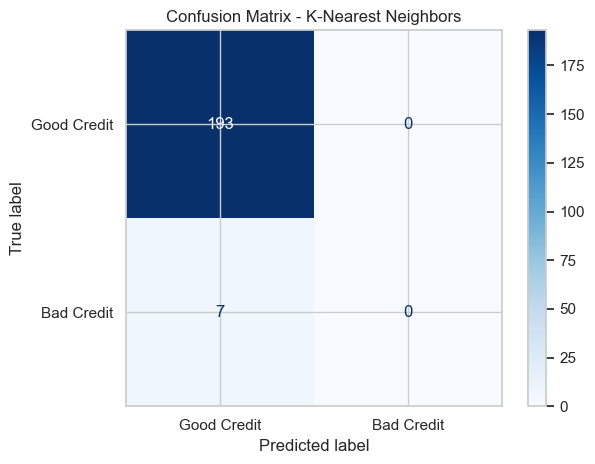

\n======================================================================
Logistic Regression
                 precision    recall  f1-score   support

Good Credit (0)       0.97      0.66      0.79       193
 Bad Credit (1)       0.04      0.43      0.08         7

       accuracy                           0.66       200
      macro avg       0.51      0.55      0.43       200
   weighted avg       0.94      0.66      0.76       200



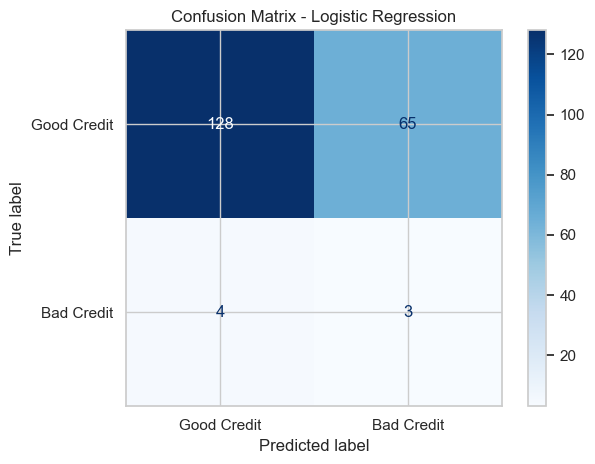

\n======================================================================
Decision Tree
                 precision    recall  f1-score   support

Good Credit (0)       0.96      0.97      0.97       193
 Bad Credit (1)       0.00      0.00      0.00         7

       accuracy                           0.94       200
      macro avg       0.48      0.49      0.48       200
   weighted avg       0.93      0.94      0.94       200



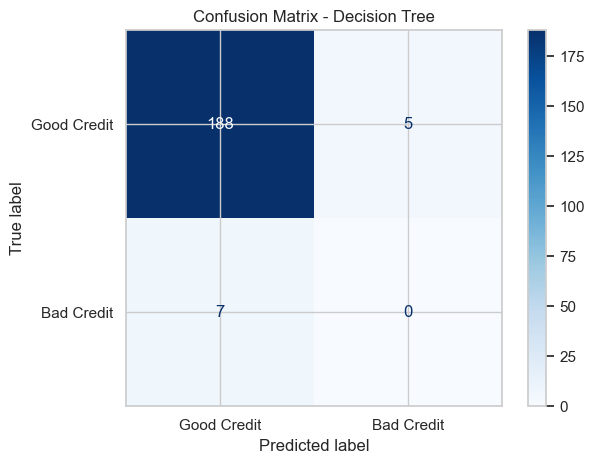

\n======================================================================
Random Forest
                 precision    recall  f1-score   support

Good Credit (0)       0.96      1.00      0.98       193
 Bad Credit (1)       0.00      0.00      0.00         7

       accuracy                           0.96       200
      macro avg       0.48      0.50      0.49       200
   weighted avg       0.93      0.96      0.95       200



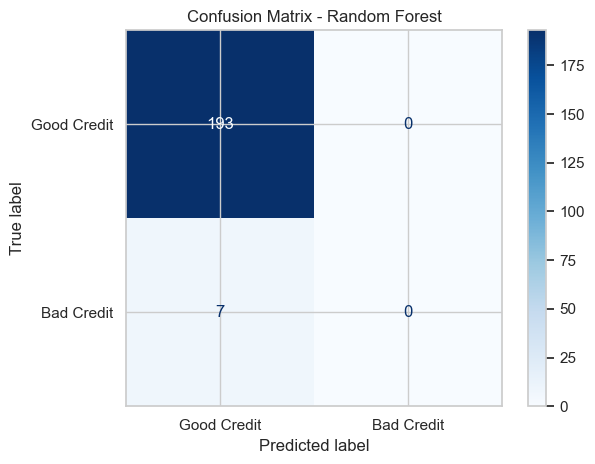

\n======================================================================
Gradient Boosting
                 precision    recall  f1-score   support

Good Credit (0)       0.96      1.00      0.98       193
 Bad Credit (1)       0.00      0.00      0.00         7

       accuracy                           0.96       200
      macro avg       0.48      0.50      0.49       200
   weighted avg       0.93      0.96      0.95       200



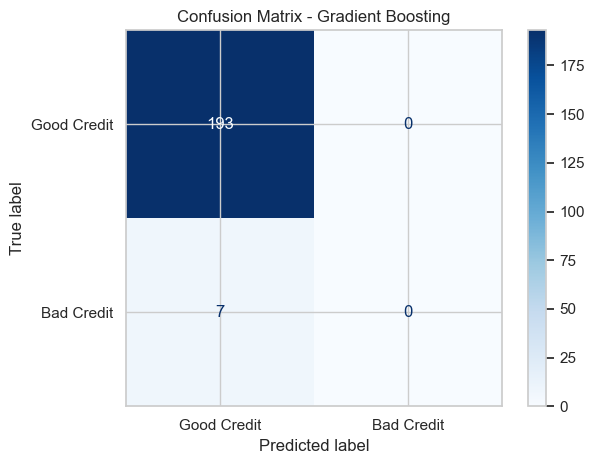

In [14]:
for name, model in trained_models.items():
    predictions = model.predict(X_test)
    print("\\n" + "=" * 70)
    print(name)
    print(classification_report(
        y_test, predictions, labels=[0, 1],
        target_names=["Good Credit (0)", "Bad Credit (1)"],
        zero_division=0
    ))
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions, labels=[0, 1],
        display_labels=["Good Credit", "Bad Credit"], cmap="Blues", values_format="d"
    )
    plt.title(f"Confusion Matrix - {name}")
    plt.tight_layout()
    plt.show()

## 10. Model comparison

PR-AUC (average precision) is emphasized because the Bad Credit class is expected to be rare. Recall for Bad Credit is also important because it measures how many actual bad-credit cases the model identifies. Do not choose a model from accuracy alone.

,Accuracy,Precision (Bad),Recall (Bad),F1 (Bad),ROC-AUC,PR-AUC / Average Precision
Model,,,,,,
Random Forest,0.965,0.000000,0.000000,0.00,0.579201,0.080036
Gradient Boosting,0.965,0.000000,0.000000,0.00,0.527017,0.079890
Logistic Regression,0.655,0.044118,0.428571,0.08,0.544782,0.059277
K-Nearest Neighbors,0.965,0.000000,0.000000,0.00,0.586232,0.049845
Decision Tree,0.940,0.000000,0.000000,0.00,0.487047,0.035000


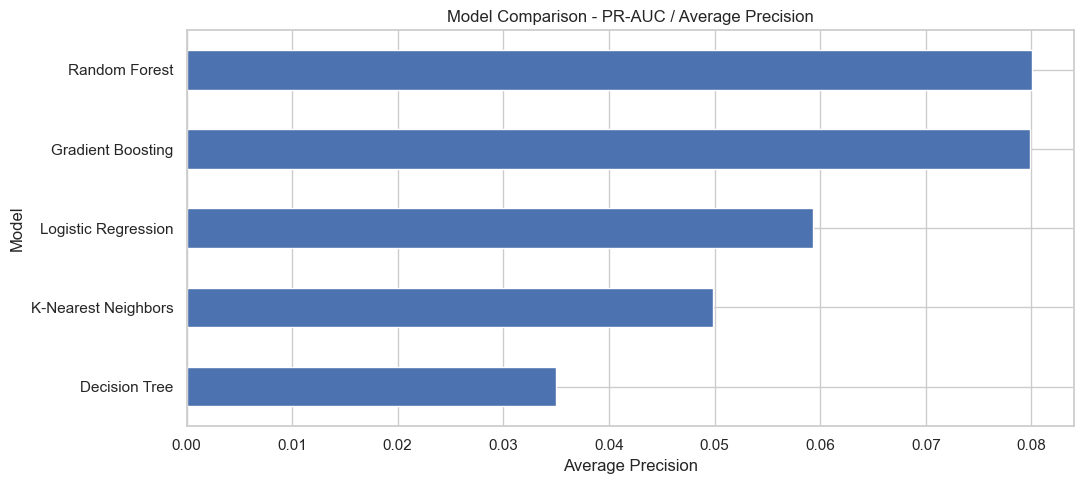

In [15]:
comparison = results_df.copy()
display(comparison)

plt.figure(figsize=(11, 5))
comparison["PR-AUC / Average Precision"].sort_values().plot(kind="barh")
plt.title("Model Comparison - PR-AUC / Average Precision")
plt.xlabel("Average Precision")
plt.ylabel("Model")
plt.tight_layout()
plt.show()

## 11. Gradient Boosting hyperparameter tuning

`GridSearchCV` tests a defined set of Gradient Boosting settings using stratified 5-fold cross-validation on the **training data only**. Average precision is used as the tuning score. The held-out test set remains untouched until the tuned model is evaluated.

Because the dataset is small and the minority class is limited, cross-validation scores can vary. Treat the selected settings as a candidate requiring further validation, not proof of production readiness.

In [16]:
gb_pipeline = Pipeline([
    ("preprocessor", make_preprocessor()),
    ("model", GradientBoostingClassifier(random_state=RANDOM_STATE))
])

param_grid = {
    "model__n_estimators": [50, 100, 150],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_depth": [1, 2, 3],
    "model__min_samples_leaf": [2, 4]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid_search = GridSearchCV(
    estimator=gb_pipeline,
    param_grid=param_grid,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)
print("\\nBest mean cross-validation PR-AUC:", round(grid_search.best_score_, 4))

tuned_gb = grid_search.best_estimator_

Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best parameters:
{'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__min_samples_leaf': 2, 'model__n_estimators': 50}
\nBest mean cross-validation PR-AUC: 0.2254


## 12. Evaluate tuned Gradient Boosting on the test set

,Accuracy,Precision (Bad),Recall (Bad),F1 (Bad),ROC-AUC,PR-AUC / Average Precision
Model,,,,,,
Tuned Gradient Boosting,0.960,0.000,0.000,0.000,0.519,0.091


                 precision    recall  f1-score   support

Good Credit (0)       0.96      0.99      0.98       193
 Bad Credit (1)       0.00      0.00      0.00         7

       accuracy                           0.96       200
      macro avg       0.48      0.50      0.49       200
   weighted avg       0.93      0.96      0.95       200



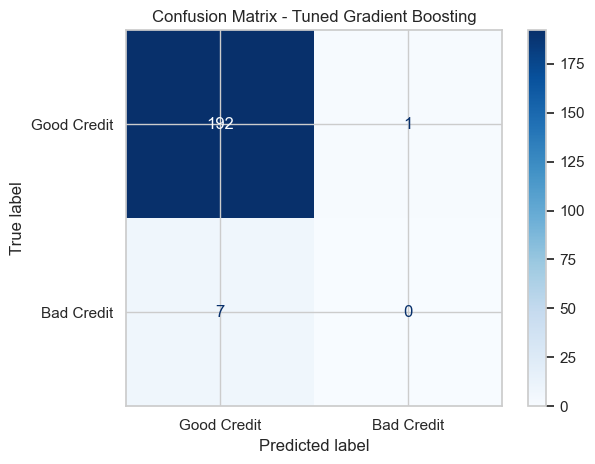

In [17]:
tuned_gb_result = evaluate_model("Tuned Gradient Boosting", tuned_gb, X_test, y_test)
tuned_gb_results_df = pd.DataFrame([tuned_gb_result]).set_index("Model")
display(tuned_gb_results_df.style.format("{:.3f}"))

print(classification_report(
    y_test, tuned_gb.predict(X_test), labels=[0, 1],
    target_names=["Good Credit (0)", "Bad Credit (1)"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test, tuned_gb.predict(X_test), labels=[0, 1],
    display_labels=["Good Credit", "Bad Credit"], cmap="Blues", values_format="d"
)
plt.title("Confusion Matrix - Tuned Gradient Boosting")
plt.tight_layout()
plt.show()

## 13. Candidate model selection

The notebook compares the five baseline models and tuned Gradient Boosting using test-set PR-AUC. The selected candidate is the model with the highest test PR-AUC. This is a transparent comparison rule for this exercise, but selecting on the test set introduces some selection optimism. A production decision should use a separate validation set or nested cross-validation and a business-approved decision threshold.

In [18]:
all_results = pd.concat([results_df, tuned_gb_results_df])
all_results = all_results.sort_values("PR-AUC / Average Precision", ascending=False)
display(all_results.style.format("{:.3f}"))

candidate_name = all_results.index[0]
if candidate_name == "Tuned Gradient Boosting":
    final_model = tuned_gb
else:
    final_model = trained_models[candidate_name]

print("Selected candidate based on test PR-AUC:", candidate_name)

,Accuracy,Precision (Bad),Recall (Bad),F1 (Bad),ROC-AUC,PR-AUC / Average Precision
Model,,,,,,
Tuned Gradient Boosting,0.960,0.000,0.000,0.000,0.519,0.091
Random Forest,0.965,0.000,0.000,0.000,0.579,0.080
Gradient Boosting,0.965,0.000,0.000,0.000,0.527,0.080
Logistic Regression,0.655,0.044,0.429,0.080,0.545,0.059
K-Nearest Neighbors,0.965,0.000,0.000,0.000,0.586,0.050
Decision Tree,0.940,0.000,0.000,0.000,0.487,0.035


Selected candidate based on test PR-AUC: Tuned Gradient Boosting


## 14. Final candidate evaluation

The following metrics describe performance on this dataset's held-out test sample. With a small number of Bad Credit cases, one or two predictions can materially change recall and precision. Report the number of positive cases alongside the metrics.

In [19]:
final_predictions = final_model.predict(X_test)
final_probabilities = final_model.predict_proba(X_test)[:, 1]

print("Selected candidate:", candidate_name)
print("Test records:", len(y_test))
print("Actual Bad Credit cases in test set:", int((y_test == 1).sum()))
print("\\nFinal classification report:")
print(classification_report(
    y_test, final_predictions, labels=[0, 1],
    target_names=["Good Credit (0)", "Bad Credit (1)"],
    zero_division=0
))

final_metrics = evaluate_model(candidate_name, final_model, X_test, y_test)
display(pd.DataFrame([final_metrics]).set_index("Model").style.format("{:.3f}"))

Selected candidate: Tuned Gradient Boosting
Test records: 200
Actual Bad Credit cases in test set: 7
\nFinal classification report:
                 precision    recall  f1-score   support

Good Credit (0)       0.96      0.99      0.98       193
 Bad Credit (1)       0.00      0.00      0.00         7

       accuracy                           0.96       200
      macro avg       0.48      0.50      0.49       200
   weighted avg       0.93      0.96      0.95       200



,Accuracy,Precision (Bad),Recall (Bad),F1 (Bad),ROC-AUC,PR-AUC / Average Precision
Model,,,,,,
Tuned Gradient Boosting,0.960,0.000,0.000,0.000,0.519,0.091


## 15. Business recommendations

Use the model as a decision-support signal, not as the sole basis for approving or rejecting credit.

1. Review Bad Credit recall and false negatives alongside the bank's acceptable risk level.
2. Review false positives to understand whether potentially good customers are being unnecessarily declined.
3. Select a probability threshold using validation data and documented business costs; do not assume 0.50 is optimal.
4. Collect more representative customer records, especially additional verified Bad Credit examples.
5. Monitor model performance and data drift after deployment.
6. Assess performance across relevant customer groups and review applicable fair-lending, privacy, and regulatory requirements.
7. Keep a human review and appeal process for consequential credit decisions.

## 16. Challenges and limitations

| Challenge / limitation | Why it matters | Recommended response |
|---|---|---|
| Small dataset | Performance estimates may be unstable | Validate on a larger, newer sample |
| Class imbalance | Accuracy can hide poor Bad Credit detection | Emphasize recall, F1, PR-AUC and confusion matrices |
| Missing values | Some records lack interest-rate or enquiry information | Impute within pipelines and investigate collection causes |
| Identifier column | Customer number is not a meaningful risk signal | Exclude `customer_no` from model features |
| Threshold choice | Default threshold may not match business risk | Tune using validation data and cost analysis |
| Fairness and explainability | Credit decisions affect customers | Conduct group-level audits and provide appropriate explanations |
| Data drift | Customer and economic patterns change | Monitor and periodically revalidate/retrain |

**Scope limitation:** The dataset alone cannot establish whether the features are legally appropriate, unbiased, current, or sufficient for real lending decisions.

## 17. Save the selected model

The saved object includes the preprocessing steps and classifier in one pipeline. Keep the model file access-controlled and do not commit customer data or trained artifacts to a public repository without explicit authorization.

In [20]:
os.makedirs("models", exist_ok=True)
model_path = os.path.join("models", "bank_good_credit_final_model.joblib")
joblib.dump(final_model, model_path)
print("Model saved to:", model_path)

# Example: load the saved pipeline
loaded_model = joblib.load(model_path)
print("Saved model loaded successfully.")

Model saved to: models\bank_good_credit_final_model.joblib
Saved model loaded successfully.


## 18. Conclusion

This project establishes an end-to-end machine-learning workflow for classifying customer credit status. Five classification algorithms are trained and compared, and Gradient Boosting is tuned using training-only cross-validation. The final candidate is selected using PR-AUC alongside class-specific metrics.

The results should be treated as an initial analytical assessment. Before any operational use, the bank should validate the model on a larger independent dataset, review the costs of different errors, set an approved probability threshold, assess fairness and explainability, and establish ongoing monitoring.

---
**Project:** Bank Good Credit Prediction  
**Target:** `Bad_label` (0 = Good Credit, 1 = Bad Credit)  
**Environment:** Python / Jupyter Notebook